In [1]:
import pandas as pd
import os

# Folder containing the datasets
folder_path = r"C:\Users\User\Desktop\Experiments_Files"

# Define file paths
weather_sensor_data_path = os.path.join(folder_path, "Plant_1_Weather_Sensor_Data.csv")
generation_data_path = os.path.join(folder_path, "Plant_1_Generation_Data.csv")
zambia_irradiance_data_path = os.path.join(folder_path, "zambia irridance data.csv")

# Load the datasets
weather_sensor_data = pd.read_csv(weather_sensor_data_path)
generation_data = pd.read_csv(generation_data_path)
zambia_irradiance_data = pd.read_csv(zambia_irradiance_data_path)

# Display the first five rows of each dataset
print("WEATHER SENSOR DATA")
display(weather_sensor_data.head())

print("GENERATION DATA")
display(generation_data.head())

print("ZAMBIA IRRADIANCE DATA")
display(zambia_irradiance_data.head())


C:\Users\User\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


WEATHER SENSOR DATA


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0


GENERATION DATA


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


ZAMBIA IRRADIANCE DATA


,YEAR,MO,DY,ALLSKY_SFC_SW_DWN,T2M,QV2M,PS
0,2017,2,1,6.20,21.38,16.03,88.79
1,2017,2,2,4.61,21.98,15.95,88.86
2,2017,2,3,3.07,21.77,16.09,88.85
3,2017,2,4,4.20,21.49,15.91,88.71
4,2017,2,5,5.01,20.83,16.12,88.68


In [2]:
# Checking for missing values in each dataset
missing_values_weather = weather_sensor_data.isnull().sum()
missing_values_generation = generation_data.isnull().sum()
missing_values_zambia = zambia_irradiance_data.isnull().sum()

# Checking for duplicates in each dataset
duplicates_weather = weather_sensor_data.duplicated().sum()
duplicates_generation = generation_data.duplicated().sum()
duplicates_zambia = zambia_irradiance_data.duplicated().sum()

# Checking for outliers using statistical summary
weather_summary = weather_sensor_data.describe()
generation_summary = generation_data.describe()
zambia_summary = zambia_irradiance_data.describe()

# Display results
missing_values_weather, duplicates_weather, weather_summary, \
missing_values_generation, duplicates_generation, generation_summary, \
missing_values_zambia, duplicates_zambia, zambia_summary


(DATE_TIME              0
 PLANT_ID               0
 SOURCE_KEY             0
 AMBIENT_TEMPERATURE    0
 MODULE_TEMPERATURE     0
 IRRADIATION            0
 dtype: int64,
 0,
         PLANT_ID  AMBIENT_TEMPERATURE  MODULE_TEMPERATURE  IRRADIATION
 count     3182.0          3182.000000         3182.000000  3182.000000
 mean   4135001.0            25.531606           31.091015     0.228313
 std          0.0             3.354856           12.261222     0.300836
 min    4135001.0            20.398505           18.140415     0.000000
 25%    4135001.0            22.705182           21.090553     0.000000
 50%    4135001.0            24.613814           24.618060     0.024653
 75%    4135001.0            27.920532           41.307840     0.449588
 max    4135001.0            35.252486           65.545714     1.221652,
 DATE_TIME      0
 PLANT_ID       0
 SOURCE_KEY     0
 DC_POWER       0
 AC_POWER       0
 DAILY_YIELD    0
 TOTAL_YIELD    0
 dtype: int64,
 0,
         PLANT_ID      DC_POWER

In [3]:
# Checking for missing values in YEAR, MO, and DY columns in Zambia dataset
missing_values_zambia_date_columns = zambia_irradiance_data[['YEAR', 'MO', 'DY']].isnull().sum()
missing_values_zambia_date_columns


YEAR    0
MO      0
DY      0
dtype: int64

In [4]:
# Display first few rows of YEAR, MO, DY columns to check for inconsistencies
zambia_irradiance_data[['YEAR', 'MO', 'DY']].head(10)


,YEAR,MO,DY
0,2017,2,1
1,2017,2,2
2,2017,2,3
3,2017,2,4
4,2017,2,5
5,2017,2,6
6,2017,2,7
7,2017,2,8
8,2017,2,9
9,2017,2,10


In [5]:
# Rename columns to match pandas' expected format for datetime conversion
zambia_irradiance_data = zambia_irradiance_data.rename(columns={'YEAR': 'year', 'MO': 'month', 'DY': 'day'})

# Convert to datetime format
zambia_irradiance_data['DATE'] = pd.to_datetime(zambia_irradiance_data[['year', 'month', 'day']])

# Check if conversion was successful
zambia_date_format_check = zambia_irradiance_data['DATE'].dtype

zambia_date_format_check


dtype('<M8[ns]')

In [6]:
# **Feature Selection and Engineering**

# Formatting Date and Time Fields

# Convert DATE_TIME in weather and generation datasets to datetime format
weather_sensor_data['DATE_TIME'] = pd.to_datetime(weather_sensor_data['DATE_TIME'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
generation_data['DATE_TIME'] = pd.to_datetime(generation_data['DATE_TIME'], format='%d-%m-%Y %H:%M', errors='coerce')

# Check if the conversion was successful
weather_sensor_data_date_format_check = weather_sensor_data['DATE_TIME'].dtype
generation_data_date_format_check = generation_data['DATE_TIME'].dtype
# **Extracting Temporal Features**
# Ensure DATE_TIME column is in datetime format
weather_sensor_data['DATE_TIME'] = pd.to_datetime(weather_sensor_data['DATE_TIME'], errors='coerce')

# Extracting features from the datetime column in Plant 1 Weather Sensor Data
weather_sensor_data['YEAR'] = weather_sensor_data['DATE_TIME'].dt.year
weather_sensor_data['MONTH'] = weather_sensor_data['DATE_TIME'].dt.month
weather_sensor_data['DAY'] = weather_sensor_data['DATE_TIME'].dt.day
weather_sensor_data['HOUR'] = weather_sensor_data['DATE_TIME'].dt.hour
weather_sensor_data['SEASON'] = weather_sensor_data['MONTH'].apply(lambda x: 'Winter' if x in [12, 1, 2]
                                                                   else 'Spring' if x in [3, 4, 5]
                                                                   else 'Summer' if x in [6, 7, 8]
                                                                   else 'Autumn')

# Extracting features from the datetime column in Plant 1 Generation Data
generation_data['YEAR'] = generation_data['DATE_TIME'].dt.year
generation_data['MONTH'] = generation_data['DATE_TIME'].dt.month
generation_data['DAY'] = generation_data['DATE_TIME'].dt.day
generation_data['HOUR'] = generation_data['DATE_TIME'].dt.hour
generation_data['SEASON'] = generation_data['MONTH'].apply(lambda x: 'Winter' if x in [12, 1, 2]
                                                            else 'Spring' if x in [3, 4, 5]
                                                            else 'Summer' if x in [6, 7, 8]
                                                            else 'Autumn')

# Extracting features from the newly created DATE column in Zambia Irradiance Data
zambia_irradiance_data['MONTH'] = zambia_irradiance_data['DATE'].dt.month
zambia_irradiance_data['DAY'] = zambia_irradiance_data['DATE'].dt.day
zambia_irradiance_data['SEASON'] = zambia_irradiance_data['MONTH'].apply(lambda x: 'Winter' if x in [12, 1, 2]
                                                                         else 'Spring' if x in [3, 4, 5]
                                                                         else 'Summer' if x in [6, 7, 8]
                                                                         else 'Autumn')

# **Normalization and Standardization**

from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Define scalers
minmax_scaler = MinMaxScaler()
standard_scaler = StandardScaler()

# Normalizing temperature values in Weather Sensor Data
weather_sensor_data[['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE']] = minmax_scaler.fit_transform(
    weather_sensor_data[['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE']])

# Normalizing temperature and pressure values in Zambia Irradiance Data
zambia_irradiance_data[['T2M', 'PS']] = minmax_scaler.fit_transform(
    zambia_irradiance_data[['T2M', 'PS']])

# Standardizing temperature values in Weather Sensor Data (alternative to normalization)
weather_sensor_data[['AMBIENT_TEMPERATURE_STD', 'MODULE_TEMPERATURE_STD']] = standard_scaler.fit_transform(
    weather_sensor_data[['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE']])

# Standardizing temperature and pressure values in Zambia Irradiance Data
zambia_irradiance_data[['T2M_STD', 'PS_STD']] = standard_scaler.fit_transform(
    zambia_irradiance_data[['T2M', 'PS']])


from IPython.display import display, Markdown

print("Weather Sensor Data (Processed)")
display(weather_sensor_data.head())

print("Generation Data (Processed)")
display(generation_data.head())

print("Zambia Irradiance Data (Processed)")
display(zambia_irradiance_data.head())


Weather Sensor Data (Processed)


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,YEAR,MONTH,DAY,HOUR,SEASON,AMBIENT_TEMPERATURE_STD,MODULE_TEMPERATURE_STD
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,0.322190,0.099506,0.0,2020,5,15,0,Spring,-0.103535,-0.671614
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,0.315477,0.097484,0.0,2020,5,15,0,Spring,-0.133266,-0.679431
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,0.305457,0.093911,0.0,2020,5,15,0,Spring,-0.177637,-0.693246
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,0.299423,0.089029,0.0,2020,5,15,0,Spring,-0.204355,-0.712126
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,0.284302,0.084906,0.0,2020,5,15,1,Spring,-0.271315,-0.728067


Generation Data (Processed)


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,YEAR,MONTH,DAY,HOUR,SEASON
0,2020-05-15,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,2020,5,15,0,Spring
1,2020-05-15,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0,2020,5,15,0,Spring
2,2020-05-15,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0,2020,5,15,0,Spring
3,2020-05-15,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0,2020,5,15,0,Spring
4,2020-05-15,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0,2020,5,15,0,Spring


Zambia Irradiance Data (Processed)


,year,month,day,ALLSKY_SFC_SW_DWN,T2M,QV2M,PS,DATE,MONTH,DAY,SEASON,T2M_STD,PS_STD
0,2017,2,1,6.20,0.482974,16.03,0.344633,2017-02-01,2,1,Winter,-0.026017,-0.828453
1,2017,2,2,4.61,0.517026,15.95,0.384181,2017-02-02,2,2,Winter,0.149361,-0.598006
2,2017,2,3,3.07,0.505108,16.09,0.378531,2017-02-03,2,3,Winter,0.087979,-0.630927
3,2017,2,4,4.20,0.489217,15.91,0.299435,2017-02-04,2,4,Winter,0.006136,-1.091821
4,2017,2,5,5.01,0.451759,16.12,0.282486,2017-02-05,2,5,Winter,-0.186780,-1.190584


In [7]:
# **Data Splitting for Model Training and Testing**

from sklearn.model_selection import train_test_split

# Define the target variable for each dataset
target_weather = 'IRRADIATION'
target_generation = 'DC_POWER'
target_zambia = 'ALLSKY_SFC_SW_DWN'

# **Splitting Plant 1 Weather Sensor Data**
# Selecting relevant features for prediction
features_weather = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'HOUR', 'DAY', 'MONTH']
X_weather = weather_sensor_data[features_weather]
y_weather = weather_sensor_data[target_weather]

# Splitting into 70% training, 15% validation, 15% test
X_train_weather, X_temp_weather, y_train_weather, y_temp_weather = train_test_split(
    X_weather, y_weather, test_size=0.3, random_state=42
)
X_val_weather, X_test_weather, y_val_weather, y_test_weather = train_test_split(
    X_temp_weather, y_temp_weather, test_size=0.5, random_state=42
)

# **Splitting Plant 1 Generation Data (for secondary correlation analysis)**
features_generation = ['HOUR', 'DAY', 'MONTH']
X_generation = generation_data[features_generation]
y_generation = generation_data[target_generation]

# Using same split ratio as weather data
X_train_gen, X_temp_gen, y_train_gen, y_temp_gen = train_test_split(
    X_generation, y_generation, test_size=0.3, random_state=42
)
X_val_gen, X_test_gen, y_val_gen, y_test_gen = train_test_split(
    X_temp_gen, y_temp_gen, test_size=0.5, random_state=42
)

# **Splitting Zambia Irradiance Data**
features_zambia = ['T2M', 'PS', 'MONTH', 'DAY']
X_zambia = zambia_irradiance_data[features_zambia]
y_zambia = zambia_irradiance_data[target_zambia]

# Using same split ratio for consistency
X_train_zambia, X_temp_zambia, y_train_zambia, y_temp_zambia = train_test_split(
    X_zambia, y_zambia, test_size=0.3, random_state=42
)
X_val_zambia, X_test_zambia, y_val_zambia, y_test_zambia = train_test_split(
    X_temp_zambia, y_temp_zambia, test_size=0.5, random_state=42
)

# **Check dataset sizes after splitting**
data_split_summary = {
    "Dataset": ["Plant 1 Weather Sensor", "Plant 1 Generation", "Zambia Irradiance"],
    "Training Size": [len(X_train_weather), len(X_train_gen), len(X_train_zambia)],
    "Validation Size": [len(X_val_weather), len(X_val_gen), len(X_val_zambia)],
    "Test Size": [len(X_test_weather), len(X_test_gen), len(X_test_zambia)]
}

# Convert results into a DataFrame for display
data_split_summary_df = pd.DataFrame(data_split_summary)

display(Markdown("### Data Split Summary"))
display(data_split_summary_df.head())

### Data Split Summary

,Dataset,Training Size,Validation Size,Test Size
0,Plant 1 Weather Sensor,2227,477,478
1,Plant 1 Generation,48144,10317,10317
2,Zambia Irradiance,1023,219,220


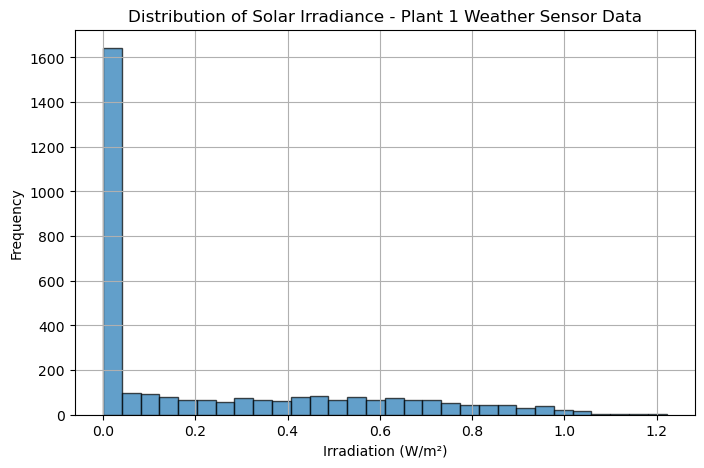

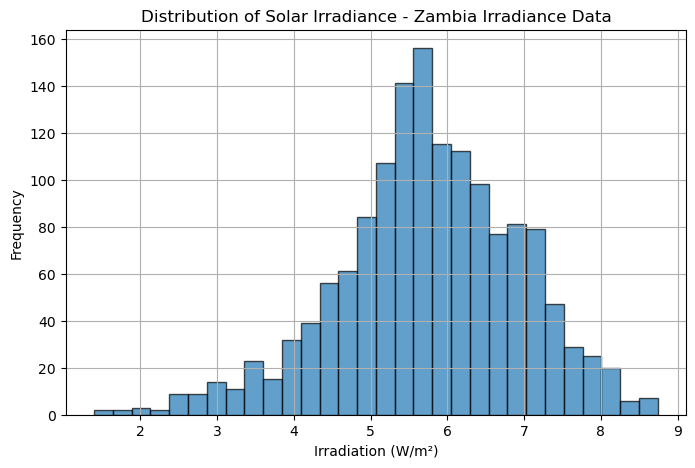

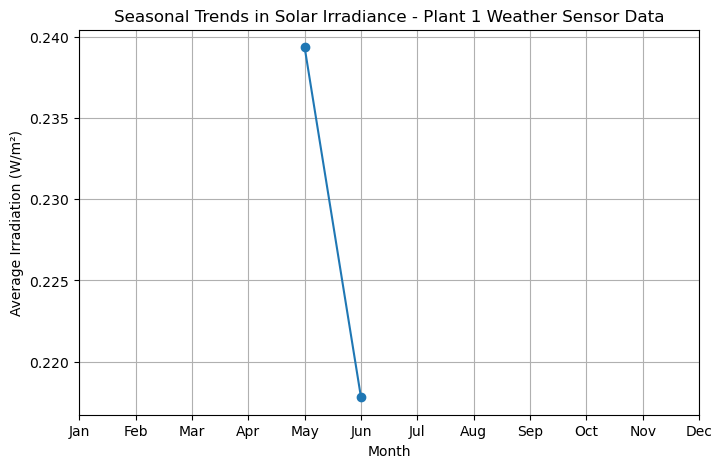

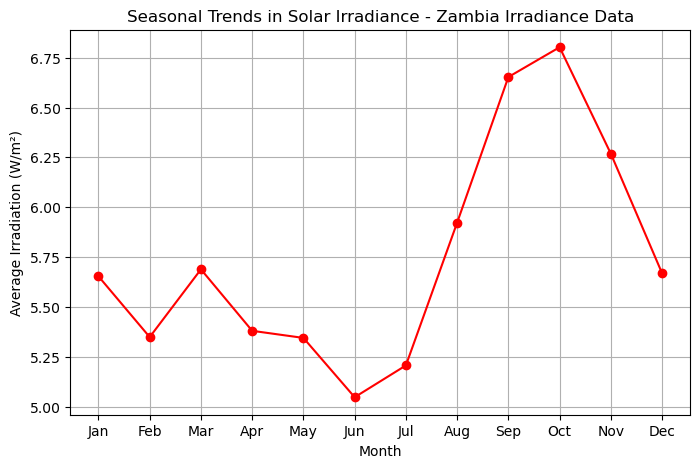

In [8]:
import matplotlib.pyplot as plt

# **Exploratory Data Analysis (EDA) - Statistical Analysis of Features**

# **Distribution of Solar Irradiance Values**

# Plot distribution of solar irradiance for Plant 1 Weather Sensor Data
plt.figure(figsize=(8, 5))
plt.hist(weather_sensor_data['IRRADIATION'], bins=30, alpha=0.7, edgecolor='black')
plt.xlabel('Irradiation (W/m²)')
plt.ylabel('Frequency')
plt.title('Distribution of Solar Irradiance - Plant 1 Weather Sensor Data')
plt.grid(True)
plt.show()

# Plot distribution of solar irradiance for Zambia Irradiance Data
plt.figure(figsize=(8, 5))
plt.hist(zambia_irradiance_data['ALLSKY_SFC_SW_DWN'], bins=30, alpha=0.7, edgecolor='black')
plt.xlabel('Irradiation (W/m²)')
plt.ylabel('Frequency')
plt.title('Distribution of Solar Irradiance - Zambia Irradiance Data')
plt.grid(True)
plt.show()

# **Trends and Seasonal Variations**

# Group data by month to analyze seasonal variations in Plant 1 Weather Sensor Data
monthly_avg_weather = weather_sensor_data.groupby('MONTH')['IRRADIATION'].mean()

# Plot seasonal trends in Plant 1 Weather Sensor Data
plt.figure(figsize=(8, 5))
plt.plot(monthly_avg_weather.index, monthly_avg_weather.values, marker='o', linestyle='-')
plt.xlabel('Month')
plt.ylabel('Average Irradiation (W/m²)')
plt.title('Seasonal Trends in Solar Irradiance - Plant 1 Weather Sensor Data')
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(True)
plt.show()

# Group data by month to analyze seasonal variations in Zambia Irradiance Data
monthly_avg_zambia = zambia_irradiance_data.groupby('MONTH')['ALLSKY_SFC_SW_DWN'].mean()

# Plot seasonal trends in Zambia Irradiance Data
plt.figure(figsize=(8, 5))
plt.plot(monthly_avg_zambia.index, monthly_avg_zambia.values, marker='o', linestyle='-', color='red')
plt.xlabel('Month')
plt.ylabel('Average Irradiation (W/m²)')
plt.title('Seasonal Trends in Solar Irradiance - Zambia Irradiance Data')
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(True)
plt.show()


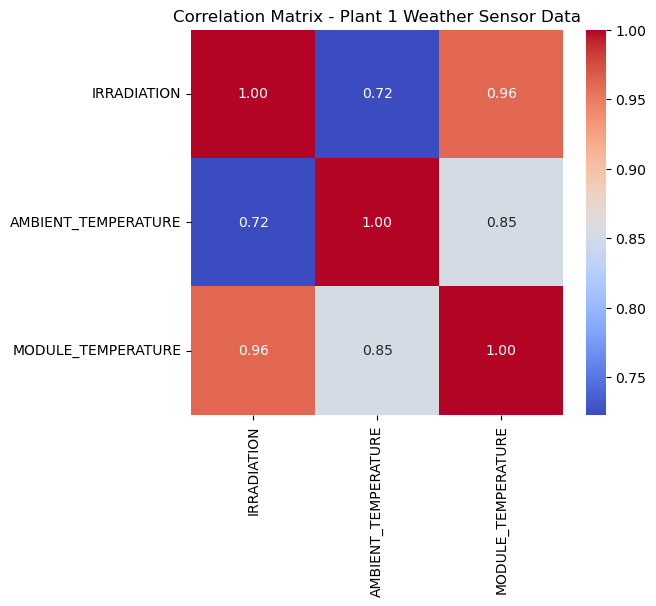

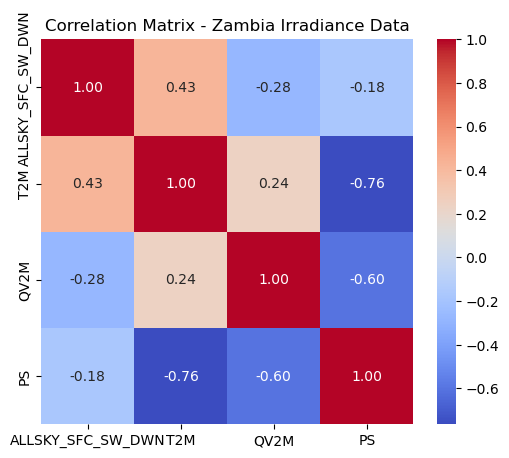

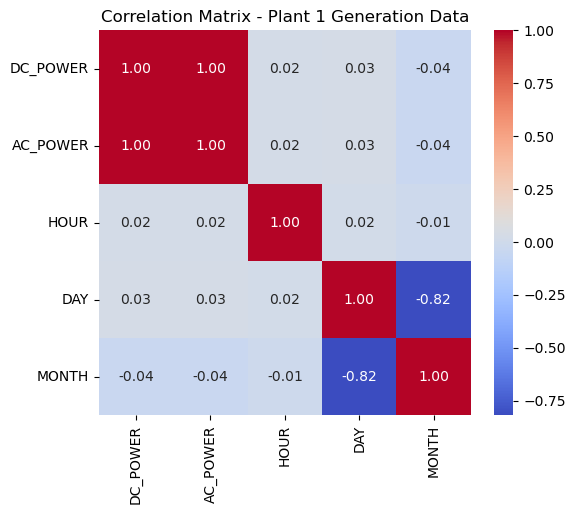

In [9]:
import seaborn as sns

# **Correlation Analysis**

# **1. Relationship between Temperature, Humidity, and Solar Irradiance**

# Selecting relevant variables from Weather Sensor Data
weather_correlation = weather_sensor_data[['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE']].corr()

# Plot heatmap for Weather Sensor Data correlation
plt.figure(figsize=(6, 5))
sns.heatmap(weather_correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix - Plant 1 Weather Sensor Data")
plt.show()

# Selecting relevant variables from Zambia Irradiance Data
zambia_correlation = zambia_irradiance_data[['ALLSKY_SFC_SW_DWN', 'T2M', 'QV2M', 'PS']].corr()

# Plot heatmap for Zambia Irradiance Data correlation
plt.figure(figsize=(6, 5))
sns.heatmap(zambia_correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix - Zambia Irradiance Data")
plt.show()

# **2. Influence of Meteorological Variables on Power Generation**

# Selecting relevant variables from Generation Data
generation_correlation = generation_data[['DC_POWER', 'AC_POWER', 'HOUR', 'DAY', 'MONTH']].corr()

# Plot heatmap for Generation Data correlation
plt.figure(figsize=(6, 5))
sns.heatmap(generation_correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix - Plant 1 Generation Data")
plt.show()


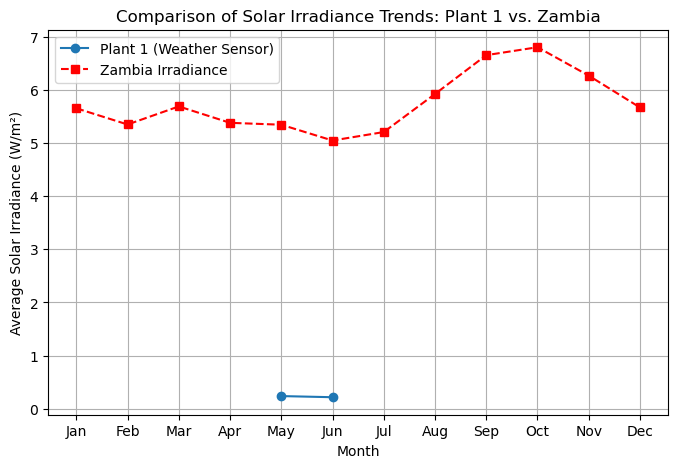

### Solar Irradiance Comparison: Plant 1 vs. Zambia

,Statistic,Plant 1 Irradiance (W/m²),Zambia Irradiance (W/m²)
0,Mean,0.228313,5.750404
1,Median,0.024653,5.760000
2,Min,0.000000,1.400000
3,Max,1.221652,8.740000
4,Standard Deviation,0.300836,1.191511


In [10]:
# **Comparative Analysis of Irradiance in Different Locations**

# **1. Analysis of Solar Irradiance Trends between Plant 1 and Zambia**

# Calculate monthly average solar irradiance for both datasets
monthly_avg_weather = weather_sensor_data.groupby('MONTH')['IRRADIATION'].mean()
monthly_avg_zambia = zambia_irradiance_data.groupby('MONTH')['ALLSKY_SFC_SW_DWN'].mean()

# Plot the comparison of monthly irradiance trends
plt.figure(figsize=(8, 5))
plt.plot(monthly_avg_weather.index, monthly_avg_weather.values, marker='o', linestyle='-', label='Plant 1 (Weather Sensor)')
plt.plot(monthly_avg_zambia.index, monthly_avg_zambia.values, marker='s', linestyle='--', label='Zambia Irradiance', color='red')
plt.xlabel('Month')
plt.ylabel('Average Solar Irradiance (W/m²)')
plt.title('Comparison of Solar Irradiance Trends: Plant 1 vs. Zambia')
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.legend()
plt.grid(True)
plt.show()

# **2. Identifying Potential Biases and Regional Variations**

# Calculate summary statistics for both datasets
weather_irradiance_stats = weather_sensor_data['IRRADIATION'].describe()
zambia_irradiance_stats = zambia_irradiance_data['ALLSKY_SFC_SW_DWN'].describe()

# Create a summary table for comparison
irradiance_comparison = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Min", "Max", "Standard Deviation"],
    "Plant 1 Irradiance (W/m²)": [
        weather_irradiance_stats['mean'],
        weather_irradiance_stats['50%'],
        weather_irradiance_stats['min'],
        weather_irradiance_stats['max'],
        weather_irradiance_stats['std']
    ],
    "Zambia Irradiance (W/m²)": [
        zambia_irradiance_stats['mean'],
        zambia_irradiance_stats['50%'],
        zambia_irradiance_stats['min'],
        zambia_irradiance_stats['max'],
        zambia_irradiance_stats['std']
    ]
})
from IPython.display import display, Markdown

display(Markdown("### Solar Irradiance Comparison: Plant 1 vs. Zambia"))
display(irradiance_comparison.head())



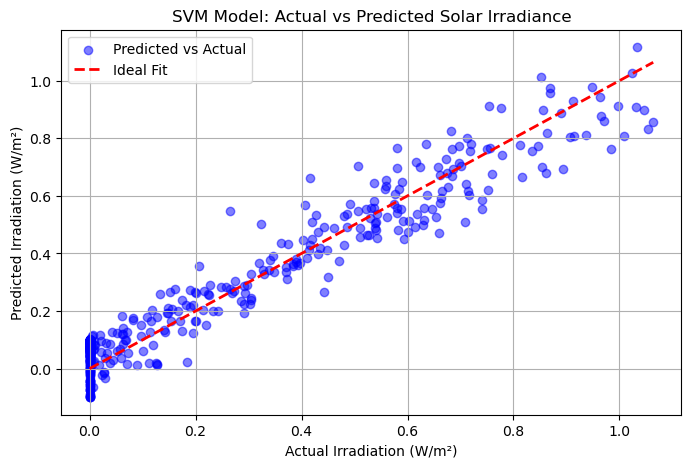

### SVM Model Performance on Plant 1 Weather Sensor Data

,Metric,Validation Score,Test Score
0,MAE,0.068598,0.067697
1,MSE,0.006857,0.006443
2,RMSE,0.082804,0.080266
3,R² Score,0.930903,0.927982


In [11]:
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# **Support Vector Machine (SVM) Model Implementation**

# **Train and Test SVM Model on Plant 1 Weather Sensor Data**

# Initialize the SVM model with a radial basis function (RBF) kernel
svm_model = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=0.1)

# Train the model
svm_model.fit(X_train_weather, y_train_weather)

# Predict on validation and test sets
y_pred_val_weather = svm_model.predict(X_val_weather)
y_pred_test_weather = svm_model.predict(X_test_weather)

# Compute performance metrics
mae_val_weather = mean_absolute_error(y_val_weather, y_pred_val_weather)
mse_val_weather = mean_squared_error(y_val_weather, y_pred_val_weather)
rmse_val_weather = mse_val_weather ** 0.5
r2_val_weather = r2_score(y_val_weather, y_pred_val_weather)

mae_test_weather = mean_absolute_error(y_test_weather, y_pred_test_weather)
mse_test_weather = mean_squared_error(y_test_weather, y_pred_test_weather)
rmse_test_weather = mse_test_weather ** 0.5
r2_test_weather = r2_score(y_test_weather, y_pred_test_weather)

# **Visualization: Actual vs Predicted Solar Irradiance**

plt.figure(figsize=(8, 5))
plt.scatter(y_test_weather, y_pred_test_weather, alpha=0.5, color='blue', label='Predicted vs Actual')
plt.plot([y_test_weather.min(), y_test_weather.max()], [y_test_weather.min(), y_test_weather.max()], 'r--', lw=2, label='Ideal Fit')
plt.xlabel('Actual Irradiation (W/m²)')
plt.ylabel('Predicted Irradiation (W/m²)')
plt.title('SVM Model: Actual vs Predicted Solar Irradiance')
plt.legend()
plt.grid(True)
plt.show()

# **Display Performance Metrics**
svm_results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R² Score"],
    "Validation Score": [mae_val_weather, mse_val_weather, rmse_val_weather, r2_val_weather],
    "Test Score": [mae_test_weather, mse_test_weather, rmse_test_weather, r2_test_weather]
})

from IPython.display import display, Markdown

display(Markdown("### SVM Model Performance on Plant 1 Weather Sensor Data"))
display(svm_results.head())



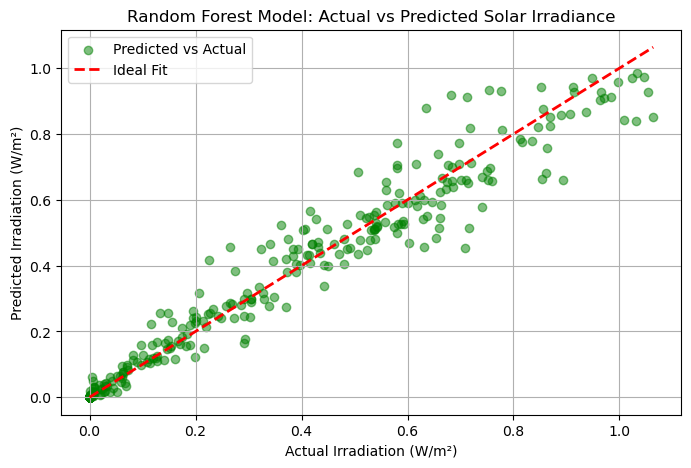

### Random Forest Model Performance on Plant 1 Weather Sensor Data

,Metric,Validation Score,Test Score
0,MAE,0.031261,0.028633
1,MSE,0.003676,0.003089
2,RMSE,0.060627,0.055576
3,R² Score,0.962959,0.965473


In [12]:
from sklearn.ensemble import RandomForestRegressor

# **Random Forest Model Implementation**

# Initialize the Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10)

# Train the model
rf_model.fit(X_train_weather, y_train_weather)

# Predict on validation and test sets
y_pred_val_rf = rf_model.predict(X_val_weather)
y_pred_test_rf = rf_model.predict(X_test_weather)

# Compute performance metrics
mae_val_rf = mean_absolute_error(y_val_weather, y_pred_val_rf)
mse_val_rf = mean_squared_error(y_val_weather, y_pred_val_rf)
rmse_val_rf = mse_val_rf ** 0.5
r2_val_rf = r2_score(y_val_weather, y_pred_val_rf)

mae_test_rf = mean_absolute_error(y_test_weather, y_pred_test_rf)
mse_test_rf = mean_squared_error(y_test_weather, y_pred_test_rf)
rmse_test_rf = mse_test_rf ** 0.5
r2_test_rf = r2_score(y_test_weather, y_pred_test_rf)

# **Visualization: Actual vs Predicted Solar Irradiance for Random Forest**

plt.figure(figsize=(8, 5))
plt.scatter(y_test_weather, y_pred_test_rf, alpha=0.5, color='green', label='Predicted vs Actual')
plt.plot([y_test_weather.min(), y_test_weather.max()], [y_test_weather.min(), y_test_weather.max()], 'r--', lw=2, label='Ideal Fit')
plt.xlabel('Actual Irradiation (W/m²)')
plt.ylabel('Predicted Irradiation (W/m²)')
plt.title('Random Forest Model: Actual vs Predicted Solar Irradiance')
plt.legend()
plt.grid(True)
plt.show()

# **Display Performance Metrics**
rf_results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R² Score"],
    "Validation Score": [mae_val_rf, mse_val_rf, rmse_val_rf, r2_val_rf],
    "Test Score": [mae_test_rf, mse_test_rf, rmse_test_rf, r2_test_rf]
})

from IPython.display import display, Markdown

display(Markdown("### Random Forest Model Performance on Plant 1 Weather Sensor Data"))
display(rf_results.head())



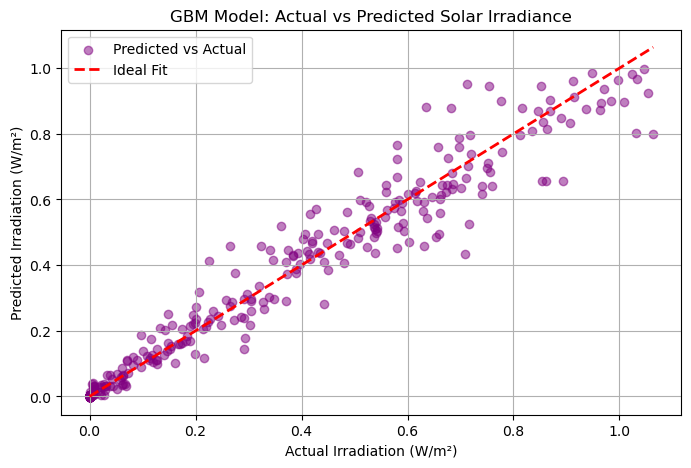

### Gradient Boosting Model Performance on Plant 1 Weather Sensor Data

,Metric,Validation Score,Test Score
0,MAE,0.030852,0.029103
1,MSE,0.003613,0.003184
2,RMSE,0.060112,0.056426
3,R² Score,0.963586,0.964408


In [13]:
from sklearn.ensemble import GradientBoostingRegressor

# **Gradient Boosting Model (GBM) Implementation**

# Initialize the Gradient Boosting Regressor
gbm_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)

# Train the model
gbm_model.fit(X_train_weather, y_train_weather)

# Predict on validation and test sets
y_pred_val_gbm = gbm_model.predict(X_val_weather)
y_pred_test_gbm = gbm_model.predict(X_test_weather)

# Compute performance metrics
mae_val_gbm = mean_absolute_error(y_val_weather, y_pred_val_gbm)
mse_val_gbm = mean_squared_error(y_val_weather, y_pred_val_gbm)
rmse_val_gbm = mse_val_gbm ** 0.5
r2_val_gbm = r2_score(y_val_weather, y_pred_val_gbm)

mae_test_gbm = mean_absolute_error(y_test_weather, y_pred_test_gbm)
mse_test_gbm = mean_squared_error(y_test_weather, y_pred_test_gbm)
rmse_test_gbm = mse_test_gbm ** 0.5
r2_test_gbm = r2_score(y_test_weather, y_pred_test_gbm)

# **Visualization: Actual vs Predicted Solar Irradiance for GBM**

plt.figure(figsize=(8, 5))
plt.scatter(y_test_weather, y_pred_test_gbm, alpha=0.5, color='purple', label='Predicted vs Actual')
plt.plot([y_test_weather.min(), y_test_weather.max()], [y_test_weather.min(), y_test_weather.max()], 'r--', lw=2, label='Ideal Fit')
plt.xlabel('Actual Irradiation (W/m²)')
plt.ylabel('Predicted Irradiation (W/m²)')
plt.title('GBM Model: Actual vs Predicted Solar Irradiance')
plt.legend()
plt.grid(True)
plt.show()

# **Display Performance Metrics**
gbm_results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R² Score"],
    "Validation Score": [mae_val_gbm, mse_val_gbm, rmse_val_gbm, r2_val_gbm],
    "Test Score": [mae_test_gbm, mse_test_gbm, rmse_test_gbm, r2_test_gbm]
})

from IPython.display import display, Markdown

display(Markdown("### Gradient Boosting Model Performance on Plant 1 Weather Sensor Data"))
display(gbm_results.head())



Epoch 1/100
70/70 [==============================] - 3s 10ms/step - loss: 0.0168 - mae: 0.0845 - val_loss: 0.0049 - val_mae: 0.0449
Epoch 2/100
70/70 [==============================] - 0s 4ms/step - loss: 0.0041 - mae: 0.0409 - val_loss: 0.0040 - val_mae: 0.0394
Epoch 3/100
70/70 [==============================] - 0s 4ms/step - loss: 0.0039 - mae: 0.0390 - val_loss: 0.0037 - val_mae: 0.0371
Epoch 4/100
70/70 [==============================] - 0s 4ms/step - loss: 0.0035 - mae: 0.0362 - val_loss: 0.0038 - val_mae: 0.0385
Epoch 5/100
70/70 [==============================] - 0s 4ms/step - loss: 0.0036 - mae: 0.0374 - val_loss: 0.0039 - val_mae: 0.0387
Epoch 6/100
70/70 [==============================] - 0s 4ms/step - loss: 0.0035 - mae: 0.0364 - val_loss: 0.0037 - val_mae: 0.0388
Epoch 7/100
70/70 [==============================] - 0s 4ms/step - loss: 0.0037 - mae: 0.0384 - val_loss: 0.0041 - val_mae: 0.0404
Epoch 8/100
70/70 [==============================] - 0s 4ms/step - loss: 0.0039 - 

70/70 [==============================] - 0s 6ms/step - loss: 0.0031 - mae: 0.0324 - val_loss: 0.0036 - val_mae: 0.0350
Epoch 64/100
70/70 [==============================] - 0s 6ms/step - loss: 0.0029 - mae: 0.0318 - val_loss: 0.0035 - val_mae: 0.0335
Epoch 65/100
70/70 [==============================] - 1s 8ms/step - loss: 0.0031 - mae: 0.0326 - val_loss: 0.0045 - val_mae: 0.0387
Epoch 66/100
70/70 [==============================] - 1s 10ms/step - loss: 0.0030 - mae: 0.0320 - val_loss: 0.0035 - val_mae: 0.0336
Epoch 67/100
70/70 [==============================] - 0s 5ms/step - loss: 0.0029 - mae: 0.0320 - val_loss: 0.0037 - val_mae: 0.0377
Epoch 68/100
70/70 [==============================] - 1s 8ms/step - loss: 0.0029 - mae: 0.0306 - val_loss: 0.0041 - val_mae: 0.0369
Epoch 69/100
70/70 [==============================] - 0s 5ms/step - loss: 0.0030 - mae: 0.0313 - val_loss: 0.0036 - val_mae: 0.0335
Epoch 70/100
70/70 [==============================] - 0s 4ms/step - loss: 0.0031 - mae: 

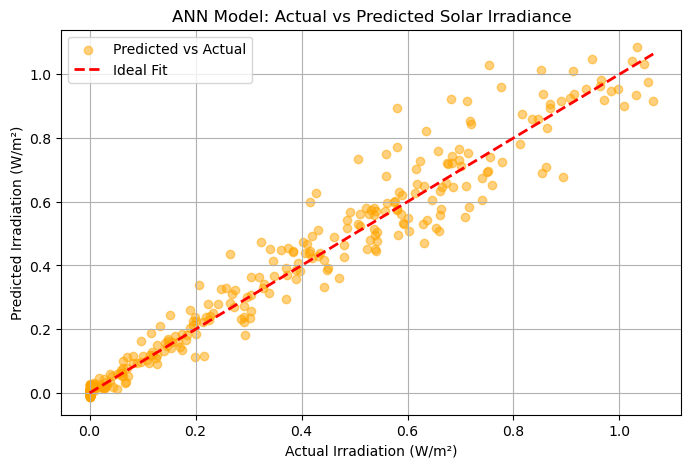

### ANN Model Performance on Plant 1 Weather Sensor Data

,Metric,Validation Score,Test Score
0,MAE,0.033536,0.030442
1,MSE,0.003764,0.003046
2,RMSE,0.061348,0.055193
3,R² Score,0.962072,0.965947


In [14]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.preprocessing import StandardScaler

# **Artificial Neural Network (ANN) Model Implementation**

# Standardize the input features for better ANN performance
scaler = StandardScaler()
X_train_weather_scaled = scaler.fit_transform(X_train_weather)
X_val_weather_scaled = scaler.transform(X_val_weather)
X_test_weather_scaled = scaler.transform(X_test_weather)

# Define the ANN architecture
ann_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_weather.shape[1],)),  # Input layer
    Dense(32, activation='relu'),  # Hidden layer 1
    Dense(16, activation='relu'),  # Hidden layer 2
    Dense(1, activation='linear')  # Output layer (regression task)
])

# Compile the model
ann_model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])

# Train the model
history = ann_model.fit(X_train_weather_scaled, y_train_weather, epochs=100, batch_size=32,
                        validation_data=(X_val_weather_scaled, y_val_weather), verbose=1)

# Predict on validation and test sets
y_pred_val_ann = ann_model.predict(X_val_weather_scaled).flatten()
y_pred_test_ann = ann_model.predict(X_test_weather_scaled).flatten()

# Compute performance metrics
mae_val_ann = mean_absolute_error(y_val_weather, y_pred_val_ann)
mse_val_ann = mean_squared_error(y_val_weather, y_pred_val_ann)
rmse_val_ann = mse_val_ann ** 0.5
r2_val_ann = r2_score(y_val_weather, y_pred_val_ann)

mae_test_ann = mean_absolute_error(y_test_weather, y_pred_test_ann)
mse_test_ann = mean_squared_error(y_test_weather, y_pred_test_ann)
rmse_test_ann = mse_test_ann ** 0.5
r2_test_ann = r2_score(y_test_weather, y_pred_test_ann)

# **Visualization: Actual vs Predicted Solar Irradiance for ANN**

plt.figure(figsize=(8, 5))
plt.scatter(y_test_weather, y_pred_test_ann, alpha=0.5, color='orange', label='Predicted vs Actual')
plt.plot([y_test_weather.min(), y_test_weather.max()], [y_test_weather.min(), y_test_weather.max()], 'r--', lw=2, label='Ideal Fit')
plt.xlabel('Actual Irradiation (W/m²)')
plt.ylabel('Predicted Irradiation (W/m²)')
plt.title('ANN Model: Actual vs Predicted Solar Irradiance')
plt.legend()
plt.grid(True)
plt.show()

# **Display Performance Metrics**
ann_results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R² Score"],
    "Validation Score": [mae_val_ann, mse_val_ann, rmse_val_ann, r2_val_ann],
    "Test Score": [mae_test_ann, mse_test_ann, rmse_test_ann, r2_test_ann]
})

from IPython.display import display, Markdown

display(Markdown("### ANN Model Performance on Plant 1 Weather Sensor Data"))
display(ann_results.head())



Epoch 1/100
70/70 [==============================] - 4s 14ms/step - loss: 0.0263 - mae: 0.1085 - val_loss: 0.0060 - val_mae: 0.0519
Epoch 2/100
70/70 [==============================] - 0s 6ms/step - loss: 0.0049 - mae: 0.0452 - val_loss: 0.0042 - val_mae: 0.0393
Epoch 3/100
70/70 [==============================] - 0s 7ms/step - loss: 0.0040 - mae: 0.0392 - val_loss: 0.0041 - val_mae: 0.0400
Epoch 4/100
70/70 [==============================] - 0s 7ms/step - loss: 0.0039 - mae: 0.0391 - val_loss: 0.0039 - val_mae: 0.0375
Epoch 5/100
70/70 [==============================] - 0s 7ms/step - loss: 0.0037 - mae: 0.0375 - val_loss: 0.0041 - val_mae: 0.0379
Epoch 6/100
70/70 [==============================] - 0s 6ms/step - loss: 0.0037 - mae: 0.0377 - val_loss: 0.0036 - val_mae: 0.0357
Epoch 7/100
70/70 [==============================] - 0s 4ms/step - loss: 0.0038 - mae: 0.0373 - val_loss: 0.0055 - val_mae: 0.0580
Epoch 8/100
70/70 [==============================] - 0s 4ms/step - loss: 0.0040 - 

70/70 [==============================] - 0s 6ms/step - loss: 0.0030 - mae: 0.0297 - val_loss: 0.0037 - val_mae: 0.0352
Epoch 64/100
70/70 [==============================] - 0s 6ms/step - loss: 0.0031 - mae: 0.0309 - val_loss: 0.0037 - val_mae: 0.0331
Epoch 65/100
70/70 [==============================] - 0s 6ms/step - loss: 0.0030 - mae: 0.0313 - val_loss: 0.0037 - val_mae: 0.0387
Epoch 66/100
70/70 [==============================] - 0s 6ms/step - loss: 0.0031 - mae: 0.0307 - val_loss: 0.0035 - val_mae: 0.0327
Epoch 67/100
70/70 [==============================] - 0s 6ms/step - loss: 0.0031 - mae: 0.0299 - val_loss: 0.0038 - val_mae: 0.0345
Epoch 68/100
70/70 [==============================] - 0s 6ms/step - loss: 0.0033 - mae: 0.0314 - val_loss: 0.0036 - val_mae: 0.0346
Epoch 69/100
70/70 [==============================] - 0s 6ms/step - loss: 0.0031 - mae: 0.0306 - val_loss: 0.0036 - val_mae: 0.0343
Epoch 70/100
70/70 [==============================] - 0s 6ms/step - loss: 0.0030 - mae: 0

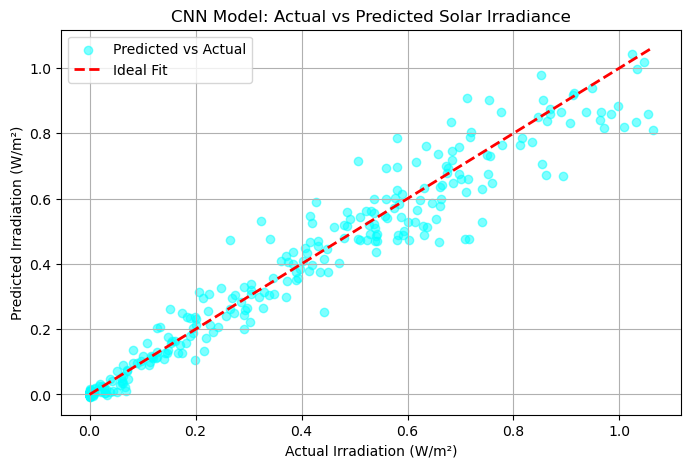

In [15]:
# Import necessary libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, Flatten, MaxPooling1D, Dropout
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import pandas as pd


# Standardize the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_weather)
X_val_scaled = scaler.transform(X_val_weather)
X_test_scaled = scaler.transform(X_test_weather)

# Reshape the data for Conv1D (samples, timesteps, features)
X_train_cnn = X_train_scaled.reshape(X_train_scaled.shape[0], X_train_scaled.shape[1], 1)
X_val_cnn = X_val_scaled.reshape(X_val_scaled.shape[0], X_val_scaled.shape[1], 1)
X_test_cnn = X_test_scaled.reshape(X_test_scaled.shape[0], X_test_scaled.shape[1], 1)


# Define the CNN model with padding to avoid negative sizes
cnn_model = Sequential([
    Conv1D(filters=32, kernel_size=3, activation='relu', padding='same', input_shape=(X_train_cnn.shape[1], 1)),
    MaxPooling1D(pool_size=2, padding='same'),
    Conv1D(filters=64, kernel_size=3, activation='relu', padding='same'),
    MaxPooling1D(pool_size=2, padding='same'),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='linear')  # Regression task
])

# Compile the model
cnn_model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])

# Train the CNN model
history = cnn_model.fit(X_train_cnn, y_train_weather, epochs=100, batch_size=32,
                        validation_data=(X_val_cnn, y_val_weather), verbose=1)

# Predict on test data
y_pred_test_cnn = cnn_model.predict(X_test_cnn).flatten()

# Calculate performance metrics
mae_cnn = mean_absolute_error(y_test_weather, y_pred_test_cnn)
mse_cnn = mean_squared_error(y_test_weather, y_pred_test_cnn)
rmse_cnn = mse_cnn ** 0.5
r2_cnn = r2_score(y_test_weather, y_pred_test_cnn)

# Display performance results
cnn_results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R² Score"],
    "Test Score": [mae_cnn, mse_cnn, rmse_cnn, r2_cnn]
})
print(cnn_results)

# Visualize Actual vs Predicted Values
plt.figure(figsize=(8, 5))
plt.scatter(y_test_weather, y_pred_test_cnn, alpha=0.5, color='cyan', label='Predicted vs Actual')
plt.plot([y_test_weather.min(), y_test_weather.max()], [y_test_weather.min(), y_test_weather.max()], 'r--', lw=2, label='Ideal Fit')
plt.xlabel('Actual Irradiation (W/m²)')
plt.ylabel('Predicted Irradiation (W/m²)')
plt.title('CNN Model: Actual vs Predicted Solar Irradiance')
plt.legend()
plt.grid(True)
plt.show()


In [17]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ==========================================
# TRAINING ON ZAMBIA DATASET (Primary Study)
# ==========================================

# 1. Scale the Zambia data
scaler_zambia = StandardScaler()
X_train_zambia_scaled = scaler_zambia.fit_transform(X_train_zambia)
X_val_zambia_scaled   = scaler_zambia.transform(X_val_zambia)
X_test_zambia_scaled  = scaler_zambia.transform(X_test_zambia)

# ----------------------------------------------------------
# 2. SVM on Zambia
# ----------------------------------------------------------
svm_model_zambia = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=0.1)
svm_model_zambia.fit(X_train_zambia_scaled, y_train_zambia)
y_pred_svm_zambia = svm_model_zambia.predict(X_test_zambia_scaled)

mae_svm  = mean_absolute_error(y_test_zambia, y_pred_svm_zambia)
rmse_svm = np.sqrt(mean_squared_error(y_test_zambia, y_pred_svm_zambia))
r2_svm   = r2_score(y_test_zambia, y_pred_svm_zambia)
print(f"Zambia SVM  — MAE: {mae_svm:.4f} | RMSE: {rmse_svm:.4f} | R²: {r2_svm:.4f}")

# ----------------------------------------------------------
# 3. Random Forest on Zambia
# ----------------------------------------------------------
rf_model_zambia = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10)
rf_model_zambia.fit(X_train_zambia_scaled, y_train_zambia)
y_pred_rf_zambia = rf_model_zambia.predict(X_test_zambia_scaled)

mae_rf  = mean_absolute_error(y_test_zambia, y_pred_rf_zambia)
rmse_rf = np.sqrt(mean_squared_error(y_test_zambia, y_pred_rf_zambia))
r2_rf   = r2_score(y_test_zambia, y_pred_rf_zambia)
print(f"Zambia RF   — MAE: {mae_rf:.4f} | RMSE: {rmse_rf:.4f} | R²: {r2_rf:.4f}")

# ----------------------------------------------------------
# 4. GBM on Zambia
# ----------------------------------------------------------
gbm_model_zambia = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
gbm_model_zambia.fit(X_train_zambia_scaled, y_train_zambia)
y_pred_gbm_zambia = gbm_model_zambia.predict(X_test_zambia_scaled)

mae_gbm  = mean_absolute_error(y_test_zambia, y_pred_gbm_zambia)
rmse_gbm = np.sqrt(mean_squared_error(y_test_zambia, y_pred_gbm_zambia))
r2_gbm   = r2_score(y_test_zambia, y_pred_gbm_zambia)
print(f"Zambia GBM  — MAE: {mae_gbm:.4f} | RMSE: {rmse_gbm:.4f} | R²: {r2_gbm:.4f}")

# ----------------------------------------------------------
# 5. ANN on Zambia
# ----------------------------------------------------------
ann_model_zambia = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_zambia_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1,  activation='linear')
])
ann_model_zambia.compile(optimizer='adam', loss='mean_squared_error')
ann_model_zambia.fit(
    X_train_zambia_scaled, y_train_zambia,
    epochs=100, batch_size=32,
    validation_data=(X_val_zambia_scaled, y_val_zambia),
    verbose=0
)
y_pred_ann_zambia = ann_model_zambia.predict(X_test_zambia_scaled).flatten()

mae_ann  = mean_absolute_error(y_test_zambia, y_pred_ann_zambia)
rmse_ann = np.sqrt(mean_squared_error(y_test_zambia, y_pred_ann_zambia))
r2_ann   = r2_score(y_test_zambia, y_pred_ann_zambia)
print(f"Zambia ANN  — MAE: {mae_ann:.4f} | RMSE: {rmse_ann:.4f} | R²: {r2_ann:.4f}")

# ----------------------------------------------------------
# 6. CNN on Zambia
# ----------------------------------------------------------
X_train_zambia_cnn = X_train_zambia_scaled.reshape(X_train_zambia_scaled.shape[0], X_train_zambia_scaled.shape[1], 1)
X_val_zambia_cnn   = X_val_zambia_scaled.reshape(X_val_zambia_scaled.shape[0], X_val_zambia_scaled.shape[1], 1)
X_test_zambia_cnn  = X_test_zambia_scaled.reshape(X_test_zambia_scaled.shape[0], X_test_zambia_scaled.shape[1], 1)

cnn_model_zambia = Sequential([
    Conv1D(filters=32, kernel_size=2, activation='relu', padding='same',
           input_shape=(X_train_zambia_cnn.shape[1], 1)),
    MaxPooling1D(pool_size=2, padding='same'),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(1,  activation='linear')
])
cnn_model_zambia.compile(optimizer='adam', loss='mean_squared_error')
cnn_model_zambia.fit(
    X_train_zambia_cnn, y_train_zambia,
    epochs=100, batch_size=32,
    validation_data=(X_val_zambia_cnn, y_val_zambia),
    verbose=0
)
y_pred_cnn_zambia = cnn_model_zambia.predict(X_test_zambia_cnn).flatten()

mae_cnn  = mean_absolute_error(y_test_zambia, y_pred_cnn_zambia)
rmse_cnn = np.sqrt(mean_squared_error(y_test_zambia, y_pred_cnn_zambia))
r2_cnn   = r2_score(y_test_zambia, y_pred_cnn_zambia)
print(f"Zambia CNN  — MAE: {mae_cnn:.4f} | RMSE: {rmse_cnn:.4f} | R²: {r2_cnn:.4f}")

# ----------------------------------------------------------
# 7. Summary Table (ready to paste into the manuscript)
# ----------------------------------------------------------
import pandas as pd
summary_zambia = pd.DataFrame({
    "Model": ["SVM", "Random Forest", "GBM", "ANN", "CNN"],
    "MAE":   [mae_svm, mae_rf, mae_gbm, mae_ann, mae_cnn],
    "RMSE":  [rmse_svm, rmse_rf, rmse_gbm, rmse_ann, rmse_cnn],
    "R2":    [r2_svm, r2_rf, r2_gbm, r2_ann, r2_cnn]
}).round(4)
print("\n===== ZAMBIA SUMMARY TABLE =====")
print(summary_zambia.to_string(index=False))

Zambia SVM  — MAE: 0.7439 | RMSE: 1.0501 | R²: 0.1911
Zambia RF   — MAE: 0.7476 | RMSE: 1.0283 | R²: 0.2244
Zambia GBM  — MAE: 0.7400 | RMSE: 1.0226 | R²: 0.2330
7/7 [==============================] - 0s 2ms/step
Zambia ANN  — MAE: 0.7084 | RMSE: 0.9824 | R²: 0.2921
7/7 [==============================] - 0s 3ms/step
Zambia CNN  — MAE: 0.7567 | RMSE: 1.0341 | R²: 0.2156

===== ZAMBIA SUMMARY TABLE =====
        Model    MAE   RMSE     R2
          SVM 0.7439 1.0501 0.1911
Random Forest 0.7476 1.0283 0.2244
          GBM 0.7400 1.0226 0.2330
          ANN 0.7084 0.9824 0.2921
          CNN 0.7567 1.0341 0.2156
